<a href="https://colab.research.google.com/github/henryparfait/kinyarwanda-news-classifier/blob/main/notebooks/03_bilstm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Models: BiLSTM with Word Embeddings

**Goal:** test whether a recurrent neural network, which reads words *in order*, beats the bag-of-words baselines, and whether **Word2Vec embeddings trained on Kinyarwanda news** help it.

| Exp | Embeddings | Pooling | What changes vs. previous |
|---|---|---|---|
| N1 | Random (learned from scratch) | Max pooling | n/a (plain BiLSTM) |
| N2 | Word2Vec (skip-gram, trained on our training set) | Max pooling | embedding initialisation |
| N3 | Word2Vec | Attention pooling | how the sequence is summarised |

**Architecture:** words → embedding layer (200-d) → bidirectional LSTM (128 units per direction) → pooling over time → dropout → linear layer → 14 class scores.



## Step 1: Install gensim, then load the data
We use gensim ≥ 4.4 because it is the first version compatible with NumPy 2.

In [ ]:
!pip install -q "gensim>=4.4.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 48.5 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, re, json, time, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

PROJECT_DIR = '/content/drive/MyDrive/kinyarwanda-news-classifier'
DATA_DIR, FIG_DIR = f'{PROJECT_DIR}/data', f'{PROJECT_DIR}/figures'
RESULTS_DIR, MODEL_DIR = f'{PROJECT_DIR}/results', f'{PROJECT_DIR}/models'
os.makedirs(MODEL_DIR, exist_ok=True)
LOG_PATH = f'{RESULTS_DIR}/experiment_log.csv'

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else '(no GPU! switch the runtime)')

train = pd.read_csv(f'{DATA_DIR}/train.csv')
val   = pd.read_csv(f'{DATA_DIR}/val.csv')
test  = pd.read_csv(f'{DATA_DIR}/test_dedup.csv')
test_orig = pd.read_csv(f'{DATA_DIR}/test.csv')
id2name = {int(k): v for k, v in json.load(open(f'{DATA_DIR}/label_map.json'))['id2name'].items()}
LABELS = sorted(id2name); NAMES = [id2name[i] for i in LABELS]
print(f'train {len(train)} | val {len(val)} | test {len(test)} | classes {len(LABELS)}')

Mounted at /content/drive
Device: cuda Tesla T4
train 6726 | val 745 | test 3464 | classes 14


## Step 2: Shared evaluation helpers

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score

def compute_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(y_true, y_pred), 'macro_precision': p, 'macro_recall': r,
            'macro_f1': f, 'weighted_f1': f1_score(y_true, y_pred, labels=LABELS, average='weighted', zero_division=0)}

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0)

def log_experiment(row):
    log = pd.read_csv(LOG_PATH)
    log = log[log['exp_id'] != row['exp_id']]
    log = pd.concat([log, pd.DataFrame([row])], ignore_index=True)
    log.to_csv(LOG_PATH, index=False)

## Step 3: Tokenisation and vocabulary
We lower-case and keep only alphabetic tokens. Splitting on apostrophes separates Kinyarwanda contractions: *n'umwana* → `n`, `umwana`, so the noun *umwana* gets the same token whether or not a particle is attached.

The vocabulary is built **only from the training set** (words seen at least twice). Any other word becomes `<unk>`. The out-of-vocabulary (OOV) rate on the test set tells us how much the model is reading blind, which matters for error analysis.

In [ ]:
TOKEN_RE = re.compile(r"[^\W\d_]+", re.UNICODE)
def tokenize(text):
    return TOKEN_RE.findall(str(text).lower())

tok_train = [tokenize(t) for t in train['text']]
tok_val   = [tokenize(t) for t in val['text']]
tok_test  = [tokenize(t) for t in test['text']]
tok_orig  = [tokenize(t) for t in test_orig['text']]

MIN_FREQ, MAX_VOCAB = 2, 50_000
counts = Counter(w for doc in tok_train for w in doc)
itos = ['<pad>', '<unk>'] + [w for w, c in counts.most_common(MAX_VOCAB) if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}

test_tokens = [w for doc in tok_test for w in doc]
oov_rate = sum(w not in stoi for w in test_tokens) / len(test_tokens)
print(f'Unique training words: {len(counts):,} | vocabulary kept: {len(itos):,}')
print(f'Test-set OOV rate (tokens not in vocabulary): {oov_rate:.2%}')
print('Example:', tok_train[0][:20])

Unique training words: 140,349 | vocabulary kept: 50,002
Test-set OOV rate (tokens not in vocabulary): 7.77%
Example: ['miss', 'nishimwe', 'naomie', 'hagati', 'ya', 'miss', 'naomie', 'na', 'rwanda', 'inspiration', 'backup', 'nishimwe', 'naomie', 'miss', 'rwanda', 'yatangaje', 'ko', 'inyungu', 'ze', 'nka']


## Step 4: Convert text to fixed-length index sequences
`MAX_LEN = 400` tokens covers the full text of most articles (median ≈ 290 words). Longer articles are truncated from the end. The title comes first, so the most informative part is always kept.

In [ ]:
MAX_LEN = 400
def encode(tok_lists):
    X = np.zeros((len(tok_lists), MAX_LEN), dtype=np.int64)
    L = np.zeros(len(tok_lists), dtype=np.int64)
    for i, toks in enumerate(tok_lists):
        ids = [stoi.get(w, 1) for w in toks[:MAX_LEN]] or [1]
        X[i, :len(ids)] = ids
        L[i] = len(ids)
    return torch.tensor(X), torch.tensor(L)

Xtr, Ltr = encode(tok_train); ytr = torch.tensor(train['label_id'].values)
Xva, Lva = encode(tok_val);   yva = val['label_id'].values
Xte, Lte = encode(tok_test);  yte = test['label_id'].values
Xor, Lor = encode(tok_orig);  yor = test_orig['label_id'].values
print('Train tensor:', tuple(Xtr.shape), '| share of articles truncated:', f'{(np.array([len(t) for t in tok_train]) > MAX_LEN).mean():.1%}')

Train tensor: (6726, 400) | share of articles truncated: 29.5%


## Step 5: Train Word2Vec on the training articles
**Skip-gram** learns a vector for each word by predicting its neighbouring words, so words used in similar contexts end up close together. We train it on the *training set only*, so no test information leaks in.

Settings: 200 dimensions, context window of 5 words, words seen at least twice, 10 passes over the data.

In [ ]:
from gensim.models import Word2Vec
t0 = time.time()
w2v = Word2Vec(sentences=tok_train, vector_size=200, window=5, min_count=2, sg=1,
               negative=10, epochs=10, workers=4, seed=SEED)
print(f'Word2Vec trained in {(time.time()-t0)/60:.1f} min | {len(w2v.wv):,} word vectors')
w2v.save(f'{MODEL_DIR}/word2vec_kinnews.model')

# Sanity check: nearest neighbours of a few topic words
probe = ['umupira', 'perezida', 'ubukungu', 'indwara', 'imana', 'amafaranga', 'ikipe', 'abanyeshuri']
rows = []
for w in probe:
    if w in w2v.wv:
        rows.append({'word': w, 'nearest_neighbours': ', '.join(n for n, _ in w2v.wv.most_similar(w, topn=8))})
nn_df = pd.DataFrame(rows); nn_df.to_csv(f'{RESULTS_DIR}/word2vec_neighbours.csv', index=False)
pd.set_option('display.max_colwidth', 200); nn_df

Word2Vec trained in 5.9 min | 63,430 word vectors


,word,nearest_neighbours
0,umupira,"amaguru, mupira, bikinirwaho, amagru, izamu, ishirahamwe, riranyomoza, wamaguru"
1,perezida,"kagame, paul, nyakubahwa, prezida, repulika, umukuru, republika, repubulika"
2,ubukungu,"bukungu, buzazamuka, buziyongera, bujegajega, bizibandwaho, ryiyongeraho, ibungabungwa, butajegajega"
3,indwara,"zitandura, kanseri, ndwara, kuvura, igicuri, diabete, asima, ubuhumekero"
4,imana,"umugisha, yaremye, uwiteka, guhimbaza, abamalayika, kuramya, yesu, matayo"
5,amafaranga,"mafaranga, amafanga, amafranga, frs, isanduku, amafaraga, amayero, kubikuza"
6,ikipe,"akinira, uzatoza, kipe, abakanyujijeho, chelsea, utoza, petro, amavubi"
7,abanyeshuri,"biga, abarezi, abanyeshuli, abarimu, banyeshuri, nderabarezi, mashuri, abiga"


## Step 6: Build the embedding matrix
Each vocabulary word gets its Word2Vec vector if one exists, otherwise a small random vector. The padding row stays zero.

In [ ]:
EMB_DIM = 200
rng = np.random.default_rng(SEED)
emb_matrix = rng.normal(0, 0.1, (len(itos), EMB_DIM)).astype(np.float32)
emb_matrix[0] = 0.0
hits = 0
for w, i in stoi.items():
    if w in w2v.wv:
        emb_matrix[i] = w2v.wv[w]; hits += 1
print(f'Vocabulary words covered by Word2Vec: {hits:,}/{len(itos):,} ({hits/len(itos):.1%})')

Vocabulary words covered by Word2Vec: 50,000/50,002 (100.0%)


## Step 7: The BiLSTM model
- **Embedding layer** turns each word index into a 200-d vector.
- **Bidirectional LSTM** reads the article left-to-right and right-to-left. Each position gets a 256-d vector (128 per direction) that reflects its context.
- **Pooling** turns the whole sequence into one vector:
  - *max pooling* keeps, for each dimension, the strongest signal anywhere in the article;
  - *attention pooling* learns a score per word, applies softmax, and takes a weighted average, so we can also *see* which words the model focused on.
- Padding positions are masked out in both cases, and *packed sequences* make the LSTM skip padding entirely.
- **Dropout (0.3)** before and after the LSTM reduces overfitting on our small dataset.

In [ ]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden, n_classes, pooling='max',
                 emb_matrix=None, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        if emb_matrix is not None:
            self.emb.weight.data.copy_(torch.from_numpy(emb_matrix))
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(dropout)
        self.pooling = pooling
        if pooling == 'attention':
            self.att = nn.Linear(2 * hidden, 1)
        self.fc = nn.Linear(2 * hidden, n_classes)

    def forward(self, x, lengths):
        mask = x != 0                                            # (batch, seq)
        e = self.drop(self.emb(x))
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))  # (batch, seq, 2h)
        weights = None
        if self.pooling == 'max':
            pooled = out.masked_fill(~mask.unsqueeze(-1), -1e4).max(dim=1).values
        else:
            scores = self.att(out).squeeze(-1).masked_fill(~mask, -1e4)
            weights = torch.softmax(scores, dim=1)
            pooled = (out * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(self.drop(pooled)), weights

m = BiLSTMClassifier(len(itos), EMB_DIM, 128, len(LABELS))
print(m); print('Trainable parameters:', sum(p.numel() for p in m.parameters() if p.requires_grad))

BiLSTMClassifier(
  (emb): Embedding(50002, 200, padding_idx=0)
  (lstm): LSTM(200, 128, batch_first=True, bidirectional=True)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=14, bias=True)
)
Trainable parameters: 10341918


## Step 8: Training loop with early stopping
AdamW optimiser (lr = 1e-3), batch size 32, cross-entropy loss, gradient clipping at 1.0 (which stops LSTM gradients exploding). After every epoch we measure validation macro-F1, keep the best weights, and stop if there is no improvement for 3 epochs.

In [ ]:
@torch.no_grad()
def predict(model, X, L, bs=128):
    model.eval(); preds = []
    for i in range(0, len(X), bs):
        logits, _ = model(X[i:i+bs].to(device), L[i:i+bs])
        preds.append(logits.argmax(1).cpu())
    return torch.cat(preds).numpy()

def train_model(exp_id, model, epochs=15, lr=1e-3, patience=3, bs=32):
    torch.manual_seed(SEED)
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    crit = nn.CrossEntropyLoss()
    loader = DataLoader(TensorDataset(Xtr, Ltr, ytr), batch_size=bs, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    best_f1, best_state, bad, hist, t0 = -1.0, None, 0, [], time.time()
    for ep in range(1, epochs + 1):
        model.train(); total = 0.0
        for xb, lb, yb in loader:
            opt.zero_grad()
            logits, _ = model(xb.to(device), lb)
            loss = crit(logits, yb.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(yb)
        vf = macro_f1(yva, predict(model, Xva, Lva))
        hist.append({'epoch': ep, 'train_loss': total / len(ytr), 'val_macro_f1': vf})
        print(f'  epoch {ep:2d} | train loss {total/len(ytr):.4f} | val macro-F1 {vf:.4f}')
        if vf > best_f1:
            best_f1, bad = vf, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print(f'  early stopping (no improvement for {patience} epochs)'); break
    model.load_state_dict(best_state)
    minutes = (time.time() - t0) / 60

    h = pd.DataFrame(hist); h.to_csv(f'{RESULTS_DIR}/{exp_id}_history.csv', index=False)
    fig, ax1 = plt.subplots(figsize=(7, 3.5)); ax2 = ax1.twinx()
    ax1.plot(h.epoch, h.train_loss, 'o-', label='train loss'); ax1.set_xlabel('epoch'); ax1.set_ylabel('train loss')
    ax2.plot(h.epoch, h.val_macro_f1, 's-', color='tab:orange', label='val macro-F1'); ax2.set_ylabel('val macro-F1')
    fig.legend(loc='upper center', ncol=2); plt.title(f'{exp_id} training curve', y=1.12); plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{exp_id}_training_curve.png', dpi=200); plt.show()
    return model, best_f1, minutes

def evaluate_and_log(exp_id, name, config, model, val_f1, minutes, notes=''):
    pred = predict(model, Xte, Lte)
    m = compute_metrics(yte, pred)
    m_orig = compute_metrics(yor, predict(model, Xor, Lor))
    log_experiment({'exp_id': exp_id, 'model': name, 'config': config, 'val_macro_f1': round(val_f1, 4),
                    'test_accuracy': round(m['accuracy'], 4), 'test_macro_f1': round(m['macro_f1'], 4),
                    'test_weighted_f1': round(m['weighted_f1'], 4), 'orig_test_macro_f1': round(m_orig['macro_f1'], 4),
                    'train_time_min': round(minutes, 2), 'notes': notes})
    print(f'{exp_id}: val F1 {val_f1:.4f} | TEST acc {m["accuracy"]:.4f} macro-F1 {m["macro_f1"]:.4f} '
          f'weighted-F1 {m["weighted_f1"]:.4f} | {minutes:.1f} min')
    return pred

## Step 9: N1, BiLSTM with random embeddings

  epoch  1 | train loss 2.0383 | val macro-F1 0.1638
  epoch  2 | train loss 1.5482 | val macro-F1 0.3261
  epoch  3 | train loss 1.1839 | val macro-F1 0.3462
  epoch  4 | train loss 0.9782 | val macro-F1 0.3668
  epoch  5 | train loss 0.8356 | val macro-F1 0.4063
  epoch  6 | train loss 0.7242 | val macro-F1 0.4222
  epoch  7 | train loss 0.6254 | val macro-F1 0.4546
  epoch  8 | train loss 0.5706 | val macro-F1 0.4588
  epoch  9 | train loss 0.4714 | val macro-F1 0.4620
  epoch 10 | train loss 0.4176 | val macro-F1 0.4619
  epoch 11 | train loss 0.3461 | val macro-F1 0.5019
  epoch 12 | train loss 0.3110 | val macro-F1 0.4777
  epoch 13 | train loss 0.2568 | val macro-F1 0.5303
  epoch 14 | train loss 0.2125 | val macro-F1 0.5226
  epoch 15 | train loss 0.1891 | val macro-F1 0.5080


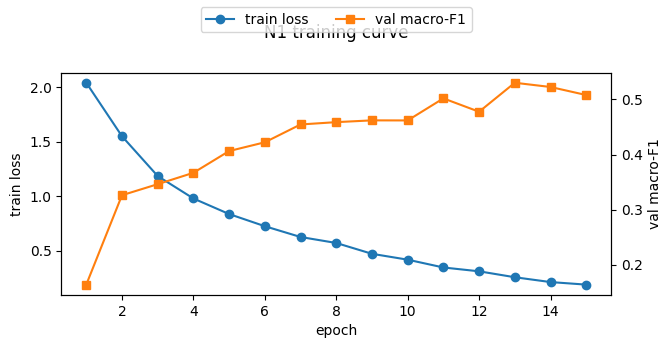

N1: val F1 0.5303 | TEST acc 0.5756 macro-F1 0.3538 weighted-F1 0.5723 | 2.1 min


In [ ]:
n1 = BiLSTMClassifier(len(itos), EMB_DIM, 128, len(LABELS), pooling='max')
n1, vf1, t1 = train_model('N1', n1)
pred_n1 = evaluate_and_log('N1', 'BiLSTM (random emb, max pool)', 'emb=200 random, hidden=128x2, max_len=400',
                           n1, vf1, t1, 'embeddings learned from scratch')

## Step 10: N2, BiLSTM with Word2Vec embeddings (one change: initialisation)

  epoch  1 | train loss 1.5419 | val macro-F1 0.3260
  epoch  2 | train loss 0.9489 | val macro-F1 0.3973
  epoch  3 | train loss 0.7609 | val macro-F1 0.4632
  epoch  4 | train loss 0.6363 | val macro-F1 0.4770
  epoch  5 | train loss 0.5135 | val macro-F1 0.4860
  epoch  6 | train loss 0.4029 | val macro-F1 0.4913
  epoch  7 | train loss 0.3019 | val macro-F1 0.5436
  epoch  8 | train loss 0.2278 | val macro-F1 0.5226
  epoch  9 | train loss 0.1671 | val macro-F1 0.4999
  epoch 10 | train loss 0.1163 | val macro-F1 0.5287
  early stopping (no improvement for 3 epochs)


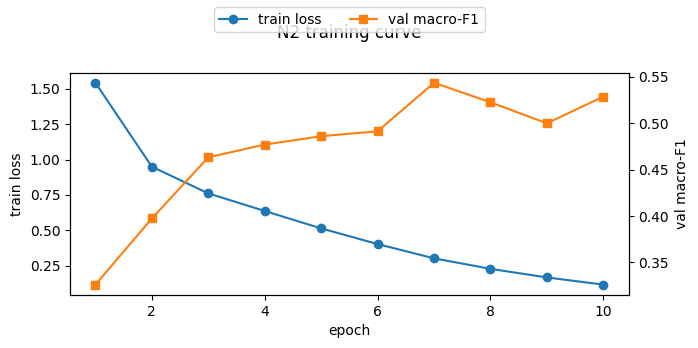

N2: val F1 0.5436 | TEST acc 0.5950 macro-F1 0.3828 weighted-F1 0.5938 | 1.4 min


In [ ]:
n2 = BiLSTMClassifier(len(itos), EMB_DIM, 128, len(LABELS), pooling='max', emb_matrix=emb_matrix)
n2, vf2, t2 = train_model('N2', n2)
pred_n2 = evaluate_and_log('N2', 'BiLSTM (Word2Vec emb, max pool)', 'emb=200 word2vec skip-gram, hidden=128x2, max_len=400',
                           n2, vf2, t2, 'word2vec init, fine-tuned')

## Step 11: N3, Word2Vec + attention pooling (one change: pooling)

  epoch  1 | train loss 1.4405 | val macro-F1 0.3391
  epoch  2 | train loss 0.9122 | val macro-F1 0.4058
  epoch  3 | train loss 0.6995 | val macro-F1 0.4761
  epoch  4 | train loss 0.5252 | val macro-F1 0.5022
  epoch  5 | train loss 0.3818 | val macro-F1 0.5505
  epoch  6 | train loss 0.2625 | val macro-F1 0.5678
  epoch  7 | train loss 0.1792 | val macro-F1 0.5926
  epoch  8 | train loss 0.1201 | val macro-F1 0.6308
  epoch  9 | train loss 0.0706 | val macro-F1 0.5971
  epoch 10 | train loss 0.0428 | val macro-F1 0.6257
  epoch 11 | train loss 0.0274 | val macro-F1 0.6230
  early stopping (no improvement for 3 epochs)


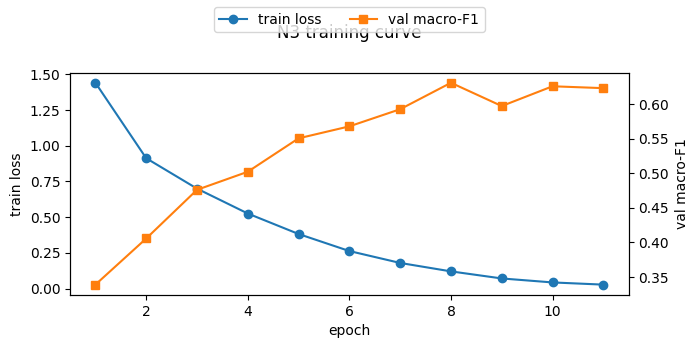

N3: val F1 0.6308 | TEST acc 0.6848 macro-F1 0.5132 weighted-F1 0.6871 | 1.6 min


In [ ]:
n3 = BiLSTMClassifier(len(itos), EMB_DIM, 128, len(LABELS), pooling='attention', emb_matrix=emb_matrix)
n3, vf3, t3 = train_model('N3', n3)
pred_n3 = evaluate_and_log('N3', 'BiLSTM (Word2Vec emb, attention pool)', 'emb=200 word2vec, hidden=128x2, attention pooling',
                           n3, vf3, t3, 'additive attention over BiLSTM states')

## Step 12: What does the attention model focus on?
For a few test articles we list the words that received the highest attention weight.

In [ ]:
@torch.no_grad()
def top_attention_words(model, idx, k=10):
    model.eval()
    _, w = model(Xte[idx:idx+1].to(device), Lte[idx:idx+1])
    n = int(Lte[idx]); w = w[0, :n].cpu().numpy()
    toks = tok_test[idx][:n]
    order = np.argsort(w)[::-1][:k]
    return ', '.join(f'{toks[j]} ({w[j]:.2f})' for j in order)

rng_idx = np.random.default_rng(SEED)
correct = np.where(pred_n3 == yte)[0]; wrong = np.where(pred_n3 != yte)[0]
rows = []
for idx in list(rng_idx.choice(correct, 3, replace=False)) + list(rng_idx.choice(wrong, min(3, len(wrong)), replace=False)):
    rows.append({'true': id2name[yte[idx]], 'pred': id2name[pred_n3[idx]],
                 'title_start': test['text'].iloc[idx][:80], 'top_attention_words': top_attention_words(n3, idx)})
att_df = pd.DataFrame(rows); att_df.to_csv(f'{RESULTS_DIR}/N3_attention_examples.csv', index=False)
att_df

,true,pred,title_start,top_attention_words
0,health,health,Umwana w'umukobwa w'imyaka 10 yibarutse umuhungu!. Umwana w'imyaka 10 y'amavuko,"muganga (0.17), src (0.11), mukobwa (0.04), ubutabera (0.04), bameze (0.04), mukobwa (0.03), byaha (0.03), nkuko (0.02), kwa (0.02), ibitaro (0.02)"
1,entertainment,entertainment,Umuhanzi Insp Badox yatangaje impamvu atari akigaragara muri muzika Nyarwanda. I,"umuhanzi (0.16), hip (0.12), bull (0.06), pacifique (0.06), hop (0.05), ruhando (0.04), muzika (0.04), oda (0.04), umuhanzi (0.04), muzika (0.03)"
2,politic,politic,Kwibuka26: Amb. Yasmin Amri Sued yasabye urubyiruko kurushaho gukurikirana amate,"uburumbuke (0.10), sylvestre (0.10), abdul (0.08), ubuvuzi (0.05), rwitabiriye (0.04), amateka (0.03), covid (0.03), kwibuka (0.03), umuhango (0.02), rugamba (0.02)"
3,entertainment,fashion,Ese birashoboka ko na twe twaha agaciro impano y'umwana mbere yo kumuhitiramo ib,"fashion (0.29), fashion (0.19), designer (0.13), izajya (0.04), designer (0.03), ikora (0.03), kubyina (0.02), nyakubahwa (0.02), ibi (0.01), city (0.01)"
4,environment,technology,Guverinoma iri kwiga ku buryo bwo kubungabunga ibirwa biri mu Rwanda. Umuyobozi,"times (0.04), new (0.04), inzobere (0.03), ibidukikije (0.03), kuganirwaho (0.03), ibidukikije (0.03), dukesha (0.02), imiti (0.02), bihingwa (0.02), byangiza (0.02)"
5,relationship,entertainment,Karahanyuze! Urukundo rwagurumanye mu byamamare rukaza gukendera. Bajya bavuga k,"nyampinga (0.28), active (0.12), urukundo (0.06), safi (0.04), miss (0.04), byamamare (0.03), akundana (0.03), active (0.02), munezero (0.02), urukundo (0.02)"


## Step 13: Save the best neural model and show the log

In [ ]:
cands = {'N1': (n1, vf1, pred_n1), 'N2': (n2, vf2, pred_n2), 'N3': (n3, vf3, pred_n3)}
best_id = max(cands, key=lambda k: cands[k][1])
best_model, _, best_pred = cands[best_id]
print('Best BiLSTM by validation macro-F1:', best_id)
torch.save({'state_dict': best_model.state_dict(), 'itos': itos, 'max_len': MAX_LEN,
            'pooling': best_model.pooling, 'emb_dim': EMB_DIM, 'hidden': 128},
           f'{MODEL_DIR}/best_bilstm.pt')
pd.DataFrame({'text': test['text'], 'true': pd.Series(yte).map(id2name),
              'pred': pd.Series(best_pred).map(id2name)}).to_csv(
    f'{RESULTS_DIR}/best_bilstm_test_predictions.csv', index=False)
pd.read_csv(LOG_PATH)

Best BiLSTM by validation macro-F1: N3


,exp_id,model,config,val_macro_f1,test_accuracy,test_macro_f1,test_weighted_f1,train_time_min,notes,orig_test_macro_f1
0,B0,Majority class,always predicts most frequent class,0.0273,0.0909,0.0119,0.0152,0.00,lower bound,NaN
1,B1,Word TF-IDF + LogReg,{'C': 10.0},0.5528,0.6911,0.4133,0.6555,3.71,word 1-2 grams,0.4062
2,B2,Char TF-IDF + LogReg,{'C': 10.0},0.6231,0.7099,0.4584,0.6812,7.50,char_wb 2-5 grams,0.4514
3,B3,Char TF-IDF + LogReg (balanced),{'C': 1.0},0.7451,0.7428,0.5773,0.7421,5.23,"char features, class_weight=balanced",0.5759
4,N1,"BiLSTM (random emb, max pool)","emb=200 random, hidden=128x2, max_len=400",0.5303,0.5756,0.3538,0.5723,2.12,embeddings learned from scratch,0.3485
5,N2,"BiLSTM (Word2Vec emb, max pool)","emb=200 word2vec skip-gram, hidden=128x2, max_len=400",0.5436,0.5950,0.3828,0.5938,1.37,"word2vec init, fine-tuned",0.3813
6,N3,"BiLSTM (Word2Vec emb, attention pool)","emb=200 word2vec, hidden=128x2, attention pooling",0.6308,0.6848,0.5132,0.6871,1.65,additive attention over BiLSTM states,0.5051
